In [1]:
# ============================================================
# AI-POWERED RESUME SCREENING & CANDIDATE RANKING SYSTEM
# ============================================================

# Import Libraries

import os
import re
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dropout,
    Dense
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [2]:
# ============================================================
# STEP 2 : DOWNLOAD NLTK STOPWORDS
# ============================================================

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

print("Stopwords loaded successfully")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Adminz\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


Stopwords loaded successfully


In [3]:
# ============================================================
# STEP 3 : CREATE PROJECT FOLDERS
# ============================================================

os.makedirs("dataset", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("reports", exist_ok=True)

print("Folders created successfully")

Folders created successfully


In [5]:
# ============================================================
# STEP 4 : LOAD DATASET
# ============================================================

import pandas as pd

df = pd.read_csv("resume_dataset_5000_people.csv")

print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset Shape: (5000, 12)

Columns:
['candidate_id', 'candidate_name', 'resume_text', 'category', 'job_role', 'skills', 'job_description', 'matched_skills', 'missing_skills', 'match_score', 'label', 'recommendation']


,candidate_id,candidate_name,resume_text,category,job_role,skills,job_description,matched_skills,missing_skills,match_score,label,recommendation
0,1,Sanjay_1,Statistics Excel Data Analysis experienced pro...,data_analyst,data_analyst,"Statistics, Excel, Data Analysis",Python SQL Power BI Excel Statistics Tableau P...,"Excel, Statistics, Data Analysis","Python, SQL, Power BI, Tableau, Pandas, NumPy,...",30.0,0,Not Suitable
1,2,Rohan_2,Machine Learning Pandas Python NumPy experienc...,data_analyst,data_analyst,"Machine Learning, Pandas, Python, NumPy",Python SQL Power BI Excel Statistics Tableau P...,"Python, Pandas, NumPy, Machine Learning","SQL, Power BI, Excel, Statistics, Tableau, Dat...",40.0,0,Not Suitable
2,3,John_3,SQL Python Keras Pandas Scikit Learn NumPy exp...,machine_learning_engineer,machine_learning_engineer,"SQL, Python, Keras, Pandas, Scikit Learn, NumPy",Python Machine Learning TensorFlow Keras NumPy...,"Python, Keras, NumPy, Pandas, Scikit Learn, SQL","Machine Learning, TensorFlow, Deep Learning, NLP",60.0,1,Moderately Suitable
3,4,Benjamin_4,NLP NumPy Python Scikit Learn Machine Learning...,machine_learning_engineer,machine_learning_engineer,"NLP, NumPy, Python, Scikit Learn, Machine Lear...",Python Machine Learning TensorFlow Keras NumPy...,"Python, Machine Learning, TensorFlow, Keras, N...",NaN,100.0,2,Highly Suitable
4,5,Michael_5,CSS Express Git JavaScript experienced profess...,full_stack_developer,full_stack_developer,"CSS, Express, Git, JavaScript",HTML CSS JavaScript React Node.js MongoDB Expr...,"CSS, JavaScript, Express, Git","HTML, React, Node.js, MongoDB, Java, Spring",40.0,0,Not Suitable


In [7]:
# ============================================================
# STEP 5 : LOAD DATASET
# ============================================================

df = pd.read_csv("resume_dataset_5000_people.csv")

print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (5000, 12)

Columns:
['candidate_id', 'candidate_name', 'resume_text', 'category', 'job_role', 'skills', 'job_description', 'matched_skills', 'missing_skills', 'match_score', 'label', 'recommendation']

First 5 Records:


,candidate_id,candidate_name,resume_text,category,job_role,skills,job_description,matched_skills,missing_skills,match_score,label,recommendation
0,1,Sanjay_1,Statistics Excel Data Analysis experienced pro...,data_analyst,data_analyst,"Statistics, Excel, Data Analysis",Python SQL Power BI Excel Statistics Tableau P...,"Excel, Statistics, Data Analysis","Python, SQL, Power BI, Tableau, Pandas, NumPy,...",30.0,0,Not Suitable
1,2,Rohan_2,Machine Learning Pandas Python NumPy experienc...,data_analyst,data_analyst,"Machine Learning, Pandas, Python, NumPy",Python SQL Power BI Excel Statistics Tableau P...,"Python, Pandas, NumPy, Machine Learning","SQL, Power BI, Excel, Statistics, Tableau, Dat...",40.0,0,Not Suitable
2,3,John_3,SQL Python Keras Pandas Scikit Learn NumPy exp...,machine_learning_engineer,machine_learning_engineer,"SQL, Python, Keras, Pandas, Scikit Learn, NumPy",Python Machine Learning TensorFlow Keras NumPy...,"Python, Keras, NumPy, Pandas, Scikit Learn, SQL","Machine Learning, TensorFlow, Deep Learning, NLP",60.0,1,Moderately Suitable
3,4,Benjamin_4,NLP NumPy Python Scikit Learn Machine Learning...,machine_learning_engineer,machine_learning_engineer,"NLP, NumPy, Python, Scikit Learn, Machine Lear...",Python Machine Learning TensorFlow Keras NumPy...,"Python, Machine Learning, TensorFlow, Keras, N...",NaN,100.0,2,Highly Suitable
4,5,Michael_5,CSS Express Git JavaScript experienced profess...,full_stack_developer,full_stack_developer,"CSS, Express, Git, JavaScript",HTML CSS JavaScript React Node.js MongoDB Expr...,"CSS, JavaScript, Express, Git","HTML, React, Node.js, MongoDB, Java, Spring",40.0,0,Not Suitable


In [8]:
# ============================================================
# STEP 6 : DATASET INFORMATION
# ============================================================

print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nLabel Distribution:")
print(df["label"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   candidate_id     5000 non-null   int64  
 1   candidate_name   5000 non-null   str    
 2   resume_text      5000 non-null   str    
 3   category         5000 non-null   str    
 4   job_role         5000 non-null   str    
 5   skills           5000 non-null   str    
 6   job_description  5000 non-null   str    
 7   matched_skills   5000 non-null   str    
 8   missing_skills   4343 non-null   str    
 9   match_score      5000 non-null   float64
 10  label            5000 non-null   int64  
 11  recommendation   5000 non-null   str    
dtypes: float64(1), int64(2), str(9)
memory usage: 468.9 KB
None

Missing Values:
candidate_id         0
candidate_name       0
resume_text          0
category             0
job_role             0
skills               0
job_description      0
matched_skills   

In [9]:
# ============================================================
# STEP 7 : CHECK JOB ROLES
# ============================================================

print(df["job_role"].value_counts())

job_role
business_analyst             1328
data_analyst                 1275
full_stack_developer         1203
machine_learning_engineer    1194
Name: count, dtype: int64


In [10]:
# ============================================================
# STEP 8 : TEXT CLEANING
# ============================================================

def clean_text(text):

    # Handle missing values
    if pd.isna(text):
        return ""

    # Convert to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove special characters
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Remove stopwords
    words = text.split()

    words = [
        word
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)


df["clean_resume_text"] = df["resume_text"].apply(clean_text)

print(df[[
    "resume_text",
    "clean_resume_text"
]].head())

                                         resume_text  \
0  Statistics Excel Data Analysis experienced pro...   
1  Machine Learning Pandas Python NumPy experienc...   
2  SQL Python Keras Pandas Scikit Learn NumPy exp...   
3  NLP NumPy Python Scikit Learn Machine Learning...   
4  CSS Express Git JavaScript experienced profess...   

                                   clean_resume_text  
0  statistics excel data analysis experienced pro...  
1  machine learning pandas python numpy experienc...  
2  sql python keras pandas scikit learn numpy exp...  
3  nlp numpy python scikit learn machine learning...  
4  css express git javascript experienced profess...  


In [11]:
# ============================================================
# STEP 8 : TEXT CLEANING
# ============================================================

def clean_text(text):

    # Handle missing values
    if pd.isna(text):
        return ""

    # Convert to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove special characters
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Remove stopwords
    words = text.split()

    words = [
        word
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)


df["clean_resume_text"] = df["resume_text"].apply(clean_text)

print(df[[
    "resume_text",
    "clean_resume_text"
]].head())

                                         resume_text  \
0  Statistics Excel Data Analysis experienced pro...   
1  Machine Learning Pandas Python NumPy experienc...   
2  SQL Python Keras Pandas Scikit Learn NumPy exp...   
3  NLP NumPy Python Scikit Learn Machine Learning...   
4  CSS Express Git JavaScript experienced profess...   

                                   clean_resume_text  
0  statistics excel data analysis experienced pro...  
1  machine learning pandas python numpy experienc...  
2  sql python keras pandas scikit learn numpy exp...  
3  nlp numpy python scikit learn machine learning...  
4  css express git javascript experienced profess...  


In [12]:
# ============================================================
# STEP 9 : TEXT LENGTH
# ============================================================

df["text_length"] = df["clean_resume_text"].apply(
    lambda x: len(x.split())
)

print(df["text_length"].describe())

count    5000.000000
mean       16.953600
std         2.961013
min        12.000000
25%        14.000000
50%        17.000000
75%        19.000000
max        22.000000
Name: text_length, dtype: float64


In [13]:
  # ============================================================
# STEP 10 : PREPARE INPUT AND OUTPUT
# ============================================================

X_text = df["clean_resume_text"]

y = df["label"].values

print("X Shape:", X_text.shape)
print("Y Shape:", y.shape)

X Shape: (5000,)
Y Shape: (5000,)


In [14]:
# ============================================================
# STEP 11 : TRAIN TEST SPLIT
# ============================================================

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train_text))
print("Testing Records :", len(X_test_text))

Training Records: 4000
Testing Records : 1000


In [15]:
# ============================================================
# STEP 12 : TOKENIZATION
# ============================================================

tokenizer = Tokenizer(
    num_words=10000,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)

print("Vocabulary Size:",
      len(tokenizer.word_index))

Vocabulary Size: 44


In [16]:
# ============================================================
# STEP 13 : TEXT TO SEQUENCES
# ============================================================

X_train_sequences = tokenizer.texts_to_sequences(
    X_train_text
)

X_test_sequences = tokenizer.texts_to_sequences(
    X_test_text
)

print("First Training Sequence:")
print(X_train_sequences[0])

First Training Sequence:
[35, 20, 22, 19, 28, 3, 4, 5, 6, 7, 8, 2, 9, 10]


In [17]:
# ============================================================
# STEP 14 : PADDING
# ============================================================

maxlen = 34

X_train = pad_sequences(
    X_train_sequences,
    maxlen=maxlen,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test_sequences,
    maxlen=maxlen,
    padding="post",
    truncating="post"
)

print("X Train Shape:", X_train.shape)
print("X Test Shape :", X_test.shape)

X Train Shape: (4000, 34)
X Test Shape : (1000, 34)


In [18]:
 # ============================================================
# STEP 15 : VOCABULARY SIZE
# ============================================================

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary Size:", vocab_size)

Vocabulary Size: 45


In [19]:
# ============================================================
# STEP 16 : SAVE TOKENIZER
# ============================================================

with open(
    "models/tokenizer.pkl",
    "wb"
) as file:

    pickle.dump(tokenizer, file)

print("Tokenizer saved successfully")

Tokenizer saved successfully


In [20]:
# ============================================================
# STEP 17 : CREATE LSTM MODEL
# ============================================================

model = Sequential([

    Input(shape=(maxlen,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=64
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(
        32,
        activation="relu"
    ),

    Dense(
        3,
        activation="softmax"
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 34, 64)              │           2,880 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │              99 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 38,083 (148.76 KB)

 Trainable params: 38,083 (148.76 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# ============================================================
# STEP 18 : COMPILE MODEL
# ============================================================

model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Model compiled successfully")

Model compiled successfully


In [22]:
# ============================================================
# STEP 19 : TRAIN MODEL
# ============================================================

history = model.fit(

    X_train,

    y_train,

    epochs=15,

    batch_size=32,

    validation_split=0.20,

    verbose=1
)

Epoch 1/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - accuracy: 0.6419 - loss: 0.7062 - val_accuracy: 0.9775 - val_loss: 0.1610
Epoch 2/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.9069 - loss: 0.2418 - val_accuracy: 0.9837 - val_loss: 0.0584
Epoch 3/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.9950 - loss: 0.0320 - val_accuracy: 0.9987 - val_loss: 0.0116
Epoch 4/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 1.0000 - loss: 0.0046 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 5/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 1.0000 - loss: 0.0024 - val_accuracy: 1.0000 - val_loss: 0.0024
Epoch 6/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 1.0000 - loss: 0.0017 - val_accuracy: 1.0000 - val_loss: 6.0201e-04
Epoch 7/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 1.0000 - loss: 9.1686e-04 - val_accuracy: 1.0000 - val_loss: 2.6566e-04
Epoch 8/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 1.0000 - loss: 7.15

In [23]:
# ============================================================
# STEP 20 : SAVE TRAINED MODEL
# ============================================================

model.save(
    "models/resume_match_model.keras"
)

print("Model saved successfully")

Model saved successfully


In [24]:
# ============================================================
# STEP 21 : MODEL EVALUATION
# ============================================================

loss, accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss     :", loss)
print("Test Accuracy :", accuracy)
print("Accuracy %    :", round(accuracy * 100, 2))

Test Loss     : 4.2871091864071786e-05
Test Accuracy : 1.0
Accuracy %    : 100.0


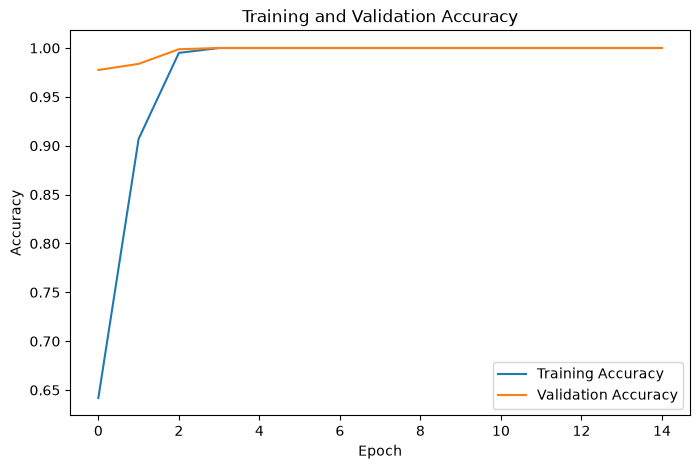

In [25]:
# ============================================================
# STEP 22 : ACCURACY CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

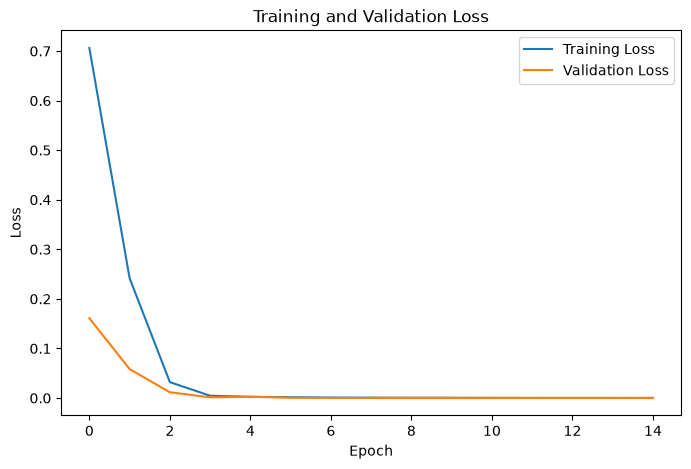

In [26]:
# ============================================================
# STEP 23 : LOSS CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [27]:
# ============================================================
# STEP 24 : MODEL PREDICTIONS
# ============================================================

y_probability = model.predict(
    X_test,
    verbose=0
)

y_pred = np.argmax(
    y_probability,
    axis=1
)

print("Predictions generated successfully")

Predictions generated successfully


In [28]:
# ============================================================
# STEP 25 : ACCURACY SCORE
# ============================================================

accuracy_score_value = accuracy_score(
    y_test,
    y_pred
)

print(
    "Accuracy:",
    round(accuracy_score_value * 100, 2),
    "%"
)

Accuracy: 100.0 %


In [30]:
 # ============================================================
# STEP 26 : CLASSIFICATION REPORT
# ============================================================

class_names = [
    "Not Suitable",
    "Moderately Suitable",
    "Highly Suitable"
]

print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names
    )
)

                     precision    recall  f1-score   support

       Not Suitable       1.00      1.00      1.00       255
Moderately Suitable       1.00      1.00      1.00       370
    Highly Suitable       1.00      1.00      1.00       375

           accuracy                           1.00      1000
          macro avg       1.00      1.00      1.00      1000
       weighted avg       1.00      1.00      1.00      1000



In [31]:
# ============================================================
# STEP 27 : CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[255   0   0]
 [  0 370   0]
 [  0   0 375]]


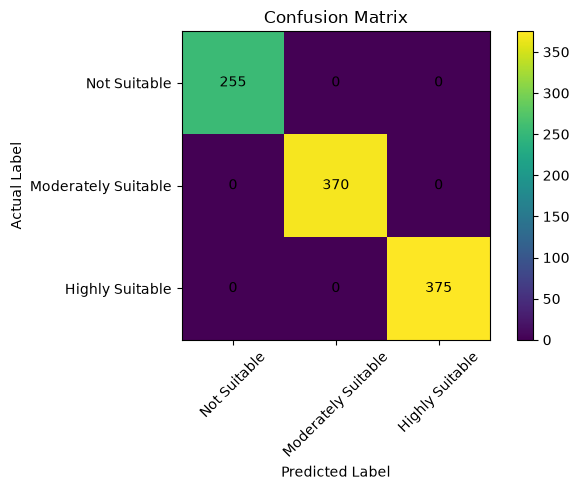

In [32]:
# ============================================================
# STEP 28 : CONFUSION MATRIX VISUALIZATION
# ============================================================

plt.figure(figsize=(7, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")

plt.xlabel("Predicted Label")

plt.ylabel("Actual Label")

plt.colorbar()

plt.xticks(
    range(3),
    class_names,
    rotation=45
)

plt.yticks(
    range(3),
    class_names
)

for i in range(3):

    for j in range(3):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.show()

In [33]:
# ============================================================
# STEP 29 : RESUME PREDICTION FUNCTION
# ============================================================

def predict_resume(resume_text):

    # Clean resume
    cleaned_text = clean_text(resume_text)

    # Convert text to sequence
    sequence = tokenizer.texts_to_sequences(
        [cleaned_text]
    )

    # Apply padding
    padded_sequence = pad_sequences(
        sequence,
        maxlen=maxlen,
        padding="post",
        truncating="post"
    )

    # Predict probabilities
    probabilities = model.predict(
        padded_sequence,
        verbose=0
    )[0]

    # Get predicted class
    predicted_class = int(
        np.argmax(probabilities)
    )

    # Confidence
    confidence = float(
        probabilities[predicted_class] * 100
    )

    class_names = {

        0: "Not Suitable",

        1: "Moderately Suitable",

        2: "Highly Suitable"
    }

    print(
        "Predicted Class :",
        class_names[predicted_class]
    )

    print(
        "Confidence      :",
        round(confidence, 2),
        "%"
    )

    return predicted_class, confidence

In [34]:
# ============================================================
# STEP 30 : TEST RESUME
# ============================================================

sample_resume = """
Python SQL Power BI Excel
Statistics Data Analysis
Machine Learning
Pandas NumPy
Dashboard Development
"""

predicted_class, confidence = predict_resume(
    sample_resume
)

Predicted Class : Moderately Suitable
Confidence      : 98.84 %


In [35]:
# ============================================================
# STEP 31 : COUNT MATCHED SKILLS
# ============================================================

def count_matched_skills(skills):

    if pd.isna(skills):

        return 0

    return len([
        skill.strip()
        for skill in str(skills).split(",")
        if skill.strip()
    ])


df["matched_skill_count"] = (
    df["matched_skills"]
    .apply(count_matched_skills)
)

print(
    df[
        [
            "candidate_name",
            "matched_skills",
            "matched_skill_count"
        ]
    ].head()
)

  candidate_name                                     matched_skills  \
0       Sanjay_1                   Excel, Statistics, Data Analysis   
1        Rohan_2            Python, Pandas, NumPy, Machine Learning   
2         John_3    Python, Keras, NumPy, Pandas, Scikit Learn, SQL   
3     Benjamin_4  Python, Machine Learning, TensorFlow, Keras, N...   
4      Michael_5                      CSS, JavaScript, Express, Git   

   matched_skill_count  
0                    3  
1                    4  
2                    6  
3                   10  
4                    4  


In [36]:
# ============================================================
# STEP 32 : SKILL MATCH CATEGORY
# ============================================================

def get_match_category(score):

    if score >= 75:

        return "Strong Match"

    elif score >= 50:

        return "Average Match"

    else:

        return "Weak Match"


df["match_category"] = (
    df["match_score"]
    .apply(get_match_category)
)

print(
    df[
        [
            "candidate_name",
            "match_score",
            "match_category"
        ]
    ].head()
)

  candidate_name  match_score match_category
0       Sanjay_1         30.0     Weak Match
1        Rohan_2         40.0     Weak Match
2         John_3         60.0  Average Match
3     Benjamin_4        100.0   Strong Match
4      Michael_5         40.0     Weak Match


In [37]:
# ============================================================
# STEP 33 : CANDIDATE RANKING FUNCTION
# ============================================================

def rank_candidates(
    job_role,
    top_n=10
):

    candidates = df[
        df["job_role"] == job_role
    ].copy()

    candidates[
        "missing_skills"
    ] = candidates[
        "missing_skills"
    ].fillna("None")

    candidates = candidates.sort_values(
        by="match_score",
        ascending=False
    )

    return candidates[
        [
            "candidate_id",
            "candidate_name",
            "job_role",
            "skills",
            "matched_skills",
            "missing_skills",
            "match_score",
            "matched_skill_count",
            "match_category",
            "label",
            "recommendation"
        ]
    ].head(top_n)

In [38]:
# ============================================================
# STEP 34 : TOP 10 DATA ANALYST CANDIDATES
# ============================================================

top_data_analysts = rank_candidates(
    "data_analyst",
    10
)

display(top_data_analysts) 

,candidate_id,candidate_name,job_role,skills,matched_skills,missing_skills,match_score,matched_skill_count,match_category,label,recommendation
55,56,Alexander_56,data_analyst,"Pandas, Excel, Machine Learning, Data Analysis...","Python, SQL, Power BI, Excel, Statistics, Tabl...",None,100.0,10,Strong Match,2,Highly Suitable
2519,2520,Alexander_2520,data_analyst,"Tableau, NumPy, Pandas, Statistics, Python, Ex...","Python, SQL, Power BI, Excel, Statistics, Tabl...",None,100.0,10,Strong Match,2,Highly Suitable
2544,2545,Kavya_2545,data_analyst,"Tableau, Pandas, Machine Learning, Data Analys...","Python, SQL, Power BI, Excel, Statistics, Tabl...",None,100.0,10,Strong Match,2,Highly Suitable
2616,2617,Chloe_2617,data_analyst,"Python, Power BI, Pandas, SQL, Tableau, Data A...","Python, SQL, Power BI, Excel, Statistics, Tabl...",None,100.0,10,Strong Match,2,Highly Suitable
2640,2641,William_2641,data_analyst,"Pandas, Machine Learning, SQL, Statistics, Pow...","Python, SQL, Power BI, Excel, Statistics, Tabl...",None,100.0,10,Strong Match,2,Highly Suitable
2642,2643,Aarav_2643,data_analyst,"Machine Learning, Pandas, Data Analysis, Pytho...","Python, SQL, Power BI, Excel, Statistics, Tabl...",None,100.0,10,Strong Match,2,Highly Suitable
114,115,Noah_115,data_analyst,"Statistics, Excel, Tableau, SQL, NumPy, Pandas...","Python, SQL, Power BI, Excel, Statistics, Tabl...",None,100.0,10,Strong Match,2,Highly Suitable
132,133,Emma_133,data_analyst,"Data Analysis, Excel, Python, Tableau, Pandas,...","Python, SQL, Power BI, Excel, Statistics, Tabl...",None,100.0,10,Strong Match,2,Highly Suitable
2702,2703,Daniel_2703,data_analyst,"Tableau, Machine Learning, SQL, Power BI, Pand...","Python, SQL, Power BI, Excel, Statistics, Tabl...",None,100.0,10,Strong Match,2,Highly Suitable
2447,2448,Divya_2448,data_analyst,"Statistics, Tableau, Power BI, Excel, SQL, Num...","Python, SQL, Power BI, Excel, Statistics, Tabl...",None,100.0,10,Strong Match,2,Highly Suitable


In [39]:
# ============================================================
# STEP 35 : TOP 10 MACHINE LEARNING ENGINEERS
# ============================================================

top_ml_engineers = rank_candidates(
    "machine_learning_engineer",
    10
)

display(top_ml_engineers)

,candidate_id,candidate_name,job_role,skills,matched_skills,missing_skills,match_score,matched_skill_count,match_category,label,recommendation
4978,4979,Mason_4979,machine_learning_engineer,"Scikit Learn, NumPy, Keras, TensorFlow, SQL, N...","Python, Machine Learning, TensorFlow, Keras, N...",None,100.0,10,Strong Match,2,Highly Suitable
4899,4900,Mia_4900,machine_learning_engineer,"TensorFlow, Pandas, Deep Learning, NumPy, Mach...","Python, Machine Learning, TensorFlow, Keras, N...",None,100.0,10,Strong Match,2,Highly Suitable
4879,4880,Meera_4880,machine_learning_engineer,"Scikit Learn, Keras, NumPy, NLP, SQL, Pandas, ...","Python, Machine Learning, TensorFlow, Keras, N...",None,100.0,10,Strong Match,2,Highly Suitable
4867,4868,Michael_4868,machine_learning_engineer,"Python, TensorFlow, Scikit Learn, SQL, Keras, ...","Python, Machine Learning, TensorFlow, Keras, N...",None,100.0,10,Strong Match,2,Highly Suitable
4859,4860,Aditya_4860,machine_learning_engineer,"Deep Learning, TensorFlow, Machine Learning, K...","Python, Machine Learning, TensorFlow, Keras, N...",None,100.0,10,Strong Match,2,Highly Suitable
104,105,Oscar_105,machine_learning_engineer,"Python, TensorFlow, Pandas, Scikit Learn, NLP,...","Python, Machine Learning, TensorFlow, Keras, N...",None,100.0,10,Strong Match,2,Highly Suitable
99,100,Sneha_100,machine_learning_engineer,"NumPy, SQL, NLP, Keras, Scikit Learn, Pandas, ...","Python, Machine Learning, TensorFlow, Keras, N...",None,100.0,10,Strong Match,2,Highly Suitable
75,76,Liam_76,machine_learning_engineer,"Deep Learning, NLP, Python, SQL, TensorFlow, M...","Python, Machine Learning, TensorFlow, Keras, N...",None,100.0,10,Strong Match,2,Highly Suitable
65,66,Michael_66,machine_learning_engineer,"Pandas, NLP, Scikit Learn, TensorFlow, Keras, ...","Python, Machine Learning, TensorFlow, Keras, N...",None,100.0,10,Strong Match,2,Highly Suitable
4787,4788,Leo_4788,machine_learning_engineer,"Machine Learning, Pandas, NLP, NumPy, Deep Lea...","Python, Machine Learning, TensorFlow, Keras, N...",None,100.0,10,Strong Match,2,Highly Suitable


In [40]:
# ============================================================
# STEP 36 : TOP 10 FULL STACK DEVELOPERS
# ============================================================

top_full_stack = rank_candidates(
    "full_stack_developer",
    10
)

display(top_full_stack)

,candidate_id,candidate_name,job_role,skills,matched_skills,missing_skills,match_score,matched_skill_count,match_category,label,recommendation
35,36,Sanjay_36,full_stack_developer,"MongoDB, CSS, HTML, React, Node.js, Git, Java,...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",None,100.0,10,Strong Match,2,Highly Suitable
53,54,Benjamin_54,full_stack_developer,"Java, Git, React, Node.js, Spring, CSS, HTML, ...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",None,100.0,10,Strong Match,2,Highly Suitable
2576,2577,Lucas_2577,full_stack_developer,"Express, HTML, Git, Java, MongoDB, CSS, JavaSc...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",None,100.0,10,Strong Match,2,Highly Suitable
4766,4767,William_4767,full_stack_developer,"Git, JavaScript, CSS, Node.js, Spring, React, ...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",None,100.0,10,Strong Match,2,Highly Suitable
4779,4780,Kavya_4780,full_stack_developer,"JavaScript, React, CSS, Spring, MongoDB, HTML,...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",None,100.0,10,Strong Match,2,Highly Suitable
4807,4808,Ava_4808,full_stack_developer,"Spring, HTML, React, JavaScript, MongoDB, Expr...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",None,100.0,10,Strong Match,2,Highly Suitable
4821,4822,Grace_4822,full_stack_developer,"Java, Express, React, Spring, HTML, MongoDB, C...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",None,100.0,10,Strong Match,2,Highly Suitable
2238,2239,Thomas_2239,full_stack_developer,"HTML, JavaScript, MongoDB, Spring, Git, CSS, N...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",None,100.0,10,Strong Match,2,Highly Suitable
2227,2228,Noah_2228,full_stack_developer,"Spring, Express, MongoDB, CSS, Java, Git, Java...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",None,100.0,10,Strong Match,2,Highly Suitable
2828,2829,Benjamin_2829,full_stack_developer,"Node.js, Express, Spring, MongoDB, JavaScript,...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",None,100.0,10,Strong Match,2,Highly Suitable


In [41]:
# ============================================================
# STEP 37 : TOP 10 BUSINESS ANALYSTS
# ============================================================

top_business_analysts = rank_candidates(
    "business_analyst",
    10
)

display(top_business_analysts)

,candidate_id,candidate_name,job_role,skills,matched_skills,missing_skills,match_score,matched_skill_count,match_category,label,recommendation
4986,4987,Lucas_4987,business_analyst,"Business Analysis, Excel, Agile, Communication...","Excel, SQL, Power BI, Tableau, Business Analys...",None,100.0,10,Strong Match,2,Highly Suitable
4988,4989,Grace_4989,business_analyst,"SQL, Excel, Documentation, Business Analysis, ...","Excel, SQL, Power BI, Tableau, Business Analys...",None,100.0,10,Strong Match,2,Highly Suitable
4923,4924,Sophia_4924,business_analyst,"Statistics, Excel, Agile, Documentation, SQL, ...","Excel, SQL, Power BI, Tableau, Business Analys...",None,100.0,10,Strong Match,2,Highly Suitable
3135,3136,Akash_3136,business_analyst,"Statistics, Documentation, Communication, Requ...","Excel, SQL, Power BI, Tableau, Business Analys...",None,100.0,10,Strong Match,2,Highly Suitable
3141,3142,Grace_3142,business_analyst,"Business Analysis, Requirements, Statistics, A...","Excel, SQL, Power BI, Tableau, Business Analys...",None,100.0,10,Strong Match,2,Highly Suitable
3143,3144,Charles_3144,business_analyst,"Communication, Documentation, Requirements, Po...","Excel, SQL, Power BI, Tableau, Business Analys...",None,100.0,10,Strong Match,2,Highly Suitable
3012,3013,Robert_3013,business_analyst,"Tableau, Statistics, Business Analysis, Power ...","Excel, SQL, Power BI, Tableau, Business Analys...",None,100.0,10,Strong Match,2,Highly Suitable
4425,4426,Rahul_4426,business_analyst,"Excel, Statistics, Agile, Documentation, Table...","Excel, SQL, Power BI, Tableau, Business Analys...",None,100.0,10,Strong Match,2,Highly Suitable
1433,1434,Olivia_1434,business_analyst,"Agile, Power BI, Statistics, Requirements, SQL...","Excel, SQL, Power BI, Tableau, Business Analys...",None,100.0,10,Strong Match,2,Highly Suitable
1446,1447,Sneha_1447,business_analyst,"Power BI, Agile, SQL, Communication, Tableau, ...","Excel, SQL, Power BI, Tableau, Business Analys...",None,100.0,10,Strong Match,2,Highly Suitable


In [42]:
# ============================================================
# STEP 38 : LSTM PREDICTIONS FOR ALL CANDIDATES
# ============================================================

all_sequences = tokenizer.texts_to_sequences(
    df["clean_resume_text"]
)

all_padded = pad_sequences(
    all_sequences,
    maxlen=maxlen,
    padding="post",
    truncating="post"
)

all_probabilities = model.predict(
    all_padded,
    verbose=0
)

df["lstm_prediction"] = np.argmax(
    all_probabilities,
    axis=1
)

df["lstm_confidence"] = (
    np.max(
        all_probabilities,
        axis=1
    ) * 100
)

print(
    df[
        [
            "candidate_name",
            "lstm_prediction",
            "lstm_confidence"
        ]
    ].head()
)

  candidate_name  lstm_prediction  lstm_confidence
0       Sanjay_1                0        99.994789
1        Rohan_2                0        99.994049
2         John_3                1        99.999786
3     Benjamin_4                2        99.997124
4      Michael_5                0        99.995232


In [43]:
# ============================================================
# STEP 39 : FINAL CANDIDATE RANKING
# ============================================================

def final_candidate_ranking(
    job_role,
    top_n=10
):

    candidates = df[
        df["job_role"] == job_role
    ].copy()

    candidates = candidates.sort_values(
        by=[
            "match_score",
            "lstm_confidence"
        ],
        ascending=False
    )

    return candidates[
        [
            "candidate_id",
            "candidate_name",
            "job_role",
            "skills",
            "matched_skills",
            "missing_skills",
            "match_score",
            "match_category",
            "lstm_prediction",
            "lstm_confidence",
            "recommendation"
        ]
    ].head(top_n)

In [44]:
# ============================================================
# STEP 40 : FINAL TOP 10 FOR EACH ROLE
# ============================================================

roles = [
    "data_analyst",
    "machine_learning_engineer",
    "full_stack_developer",
    "business_analyst"
]

for role in roles:

    print("\n")
    print("=" * 70)

    print(
        "TOP 10 CANDIDATES -",
        role.upper()
    )

    print("=" * 70)

    result = final_candidate_ranking(
        role,
        10
    )

    display(result)



TOP 10 CANDIDATES - DATA_ANALYST


,candidate_id,candidate_name,job_role,skills,matched_skills,missing_skills,match_score,match_category,lstm_prediction,lstm_confidence,recommendation
678,679,Ananya_679,data_analyst,"NumPy, Data Analysis, Machine Learning, Statis...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997269,Highly Suitable
541,542,Karthik_542,data_analyst,"Tableau, Statistics, Machine Learning, Power B...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
1411,1412,Joseph_1412,data_analyst,"Data Analysis, Tableau, SQL, NumPy, Machine Le...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
2742,2743,Liam_2743,data_analyst,"NumPy, Machine Learning, Statistics, Data Anal...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
3167,3168,Isabella_3168,data_analyst,"Data Analysis, Tableau, Machine Learning, Stat...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
3667,3668,Daniel_3668,data_analyst,"Excel, Statistics, Data Analysis, Machine Lear...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
4784,4785,Emma_4785,data_analyst,"Excel, Data Analysis, Tableau, NumPy, Machine ...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
561,562,Rohan_562,data_analyst,"Excel, Tableau, Pandas, Power BI, Machine Lear...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997246,Highly Suitable
768,769,Jack_769,data_analyst,"Tableau, Statistics, Machine Learning, SQL, Ex...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997246,Highly Suitable
796,797,Thomas_797,data_analyst,"SQL, Excel, Tableau, Data Analysis, Statistics...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997246,Highly Suitable




TOP 10 CANDIDATES - MACHINE_LEARNING_ENGINEER


,candidate_id,candidate_name,job_role,skills,matched_skills,missing_skills,match_score,match_category,lstm_prediction,lstm_confidence,recommendation
1145,1146,James_1146,machine_learning_engineer,"NumPy, Deep Learning, NLP, Scikit Learn, Keras...","Python, Machine Learning, TensorFlow, Keras, N...",NaN,100.0,Strong Match,2,99.997269,Highly Suitable
975,976,Anjali_976,machine_learning_engineer,"TensorFlow, Deep Learning, NumPy, Scikit Learn...","Python, Machine Learning, TensorFlow, Keras, N...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
2345,2346,Leo_2346,machine_learning_engineer,"Deep Learning, TensorFlow, Scikit Learn, NLP, ...","Python, Machine Learning, TensorFlow, Keras, N...",NaN,100.0,Strong Match,2,99.997238,Highly Suitable
2956,2957,Noah_2957,machine_learning_engineer,"TensorFlow, Deep Learning, Scikit Learn, Keras...","Python, Machine Learning, TensorFlow, Keras, N...",NaN,100.0,Strong Match,2,99.997238,Highly Suitable
3100,3101,Aarav_3101,machine_learning_engineer,"Keras, Scikit Learn, Deep Learning, Python, NL...","Python, Machine Learning, TensorFlow, Keras, N...",NaN,100.0,Strong Match,2,99.997238,Highly Suitable
4108,4109,Michael_4109,machine_learning_engineer,"Keras, TensorFlow, Deep Learning, NumPy, Machi...","Python, Machine Learning, TensorFlow, Keras, N...",NaN,100.0,Strong Match,2,99.997238,Highly Suitable
4939,4940,Sneha_4940,machine_learning_engineer,"Pandas, Deep Learning, Scikit Learn, Keras, Ma...","Python, Machine Learning, TensorFlow, Keras, N...",NaN,100.0,Strong Match,2,99.997238,Highly Suitable
1301,1302,Sanjay_1302,machine_learning_engineer,"Keras, TensorFlow, Deep Learning, Python, Mach...","Python, Machine Learning, TensorFlow, Keras, N...",NaN,100.0,Strong Match,2,99.997223,Highly Suitable
1323,1324,Meera_1324,machine_learning_engineer,"Deep Learning, Scikit Learn, Keras, Python, Te...","Python, Machine Learning, TensorFlow, Keras, N...",NaN,100.0,Strong Match,2,99.997223,Highly Suitable
2904,2905,Leo_2905,machine_learning_engineer,"NLP, Deep Learning, Machine Learning, NumPy, P...","Python, Machine Learning, TensorFlow, Keras, N...",NaN,100.0,Strong Match,2,99.997223,Highly Suitable




TOP 10 CANDIDATES - FULL_STACK_DEVELOPER


,candidate_id,candidate_name,job_role,skills,matched_skills,missing_skills,match_score,match_category,lstm_prediction,lstm_confidence,recommendation
582,583,Ava_583,full_stack_developer,"Express, CSS, JavaScript, Git, Spring, Node.js...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",NaN,100.0,Strong Match,2,99.997566,Highly Suitable
1496,1497,Mason_1497,full_stack_developer,"Express, Spring, CSS, Git, Node.js, Java, Reac...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",NaN,100.0,Strong Match,2,99.997566,Highly Suitable
3590,3591,Benjamin_3591,full_stack_developer,"CSS, HTML, Express, Git, MongoDB, Node.js, Jav...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",NaN,100.0,Strong Match,2,99.997543,Highly Suitable
3684,3685,Sneha_3685,full_stack_developer,"CSS, Express, Node.js, React, MongoDB, Java, G...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",NaN,100.0,Strong Match,2,99.997543,Highly Suitable
3739,3740,Chloe_3740,full_stack_developer,"CSS, Spring, Git, JavaScript, Node.js, HTML, R...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",NaN,100.0,Strong Match,2,99.997543,Highly Suitable
1166,1167,John_1167,full_stack_developer,"Express, Git, HTML, JavaScript, CSS, Node.js, ...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",NaN,100.0,Strong Match,2,99.997520,Highly Suitable
1221,1222,Kavya_1222,full_stack_developer,"CSS, Node.js, HTML, Git, React, Express, Sprin...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",NaN,100.0,Strong Match,2,99.997520,Highly Suitable
2947,2948,Charles_2948,full_stack_developer,"CSS, Java, Spring, Node.js, JavaScript, HTML, ...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",NaN,100.0,Strong Match,2,99.997520,Highly Suitable
3750,3751,Karthik_3751,full_stack_developer,"CSS, JavaScript, Git, HTML, Node.js, React, Ex...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",NaN,100.0,Strong Match,2,99.997520,Highly Suitable
3901,3902,Jack_3902,full_stack_developer,"Spring, CSS, Express, Java, React, MongoDB, No...","HTML, CSS, JavaScript, React, Node.js, MongoDB...",NaN,100.0,Strong Match,2,99.997520,Highly Suitable




TOP 10 CANDIDATES - BUSINESS_ANALYST


,candidate_id,candidate_name,job_role,skills,matched_skills,missing_skills,match_score,match_category,lstm_prediction,lstm_confidence,recommendation
1974,1975,Benjamin_1975,business_analyst,"Statistics, Tableau, Agile, Requirements, Busi...","Excel, SQL, Power BI, Tableau, Business Analys...",NaN,100.0,Strong Match,2,99.997520,Highly Suitable
2372,2373,James_2373,business_analyst,"Agile, Excel, Statistics, Power BI, SQL, Busin...","Excel, SQL, Power BI, Tableau, Business Analys...",NaN,100.0,Strong Match,2,99.997498,Highly Suitable
247,248,Grace_248,business_analyst,"Agile, Excel, Requirements, Statistics, Power ...","Excel, SQL, Power BI, Tableau, Business Analys...",NaN,100.0,Strong Match,2,99.997482,Highly Suitable
1971,1972,Mason_1972,business_analyst,"SQL, Tableau, Requirements, Statistics, Power ...","Excel, SQL, Power BI, Tableau, Business Analys...",NaN,100.0,Strong Match,2,99.997482,Highly Suitable
3456,3457,Meera_3457,business_analyst,"Tableau, Requirements, Agile, Business Analysi...","Excel, SQL, Power BI, Tableau, Business Analys...",NaN,100.0,Strong Match,2,99.997482,Highly Suitable
1433,1434,Olivia_1434,business_analyst,"Agile, Power BI, Statistics, Requirements, SQL...","Excel, SQL, Power BI, Tableau, Business Analys...",NaN,100.0,Strong Match,2,99.997475,Highly Suitable
3452,3453,Kavya_3453,business_analyst,"Agile, Excel, Power BI, Requirements, Business...","Excel, SQL, Power BI, Tableau, Business Analys...",NaN,100.0,Strong Match,2,99.997475,Highly Suitable
660,661,Chloe_661,business_analyst,"Excel, SQL, Requirements, Agile, Power BI, Tab...","Excel, SQL, Power BI, Tableau, Business Analys...",NaN,100.0,Strong Match,2,99.997459,Highly Suitable
3570,3571,Benjamin_3571,business_analyst,"Agile, Documentation, Requirements, Tableau, P...","Excel, SQL, Power BI, Tableau, Business Analys...",NaN,100.0,Strong Match,2,99.997459,Highly Suitable
3815,3816,Rohan_3816,business_analyst,"Requirements, Agile, Statistics, Business Anal...","Excel, SQL, Power BI, Tableau, Business Analys...",NaN,100.0,Strong Match,2,99.997459,Highly Suitable


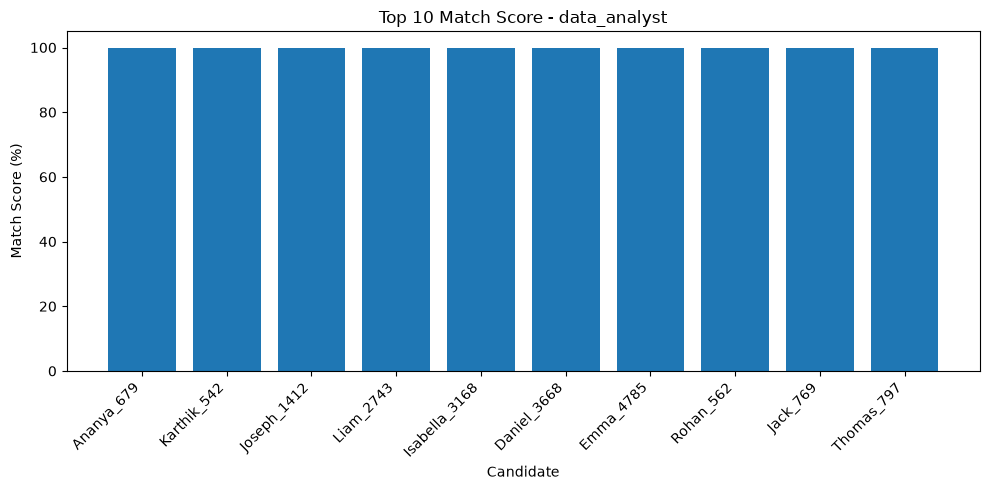

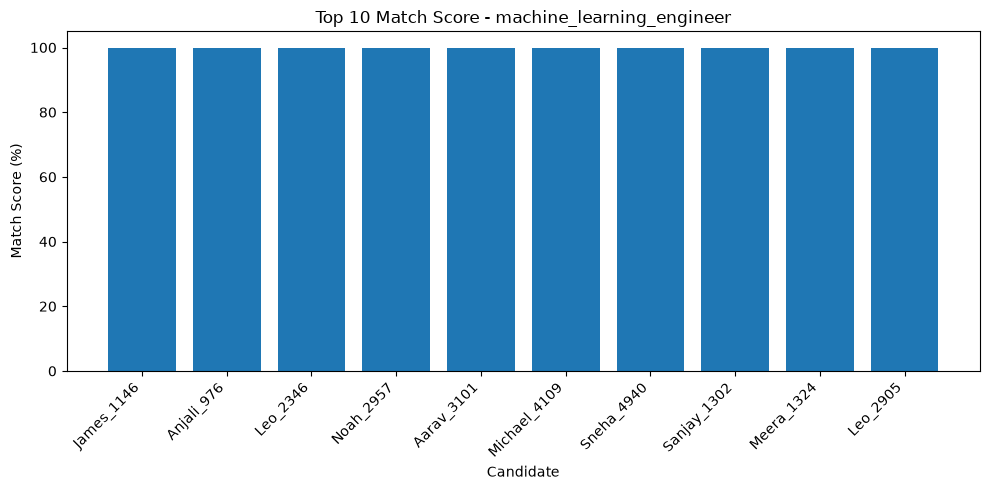

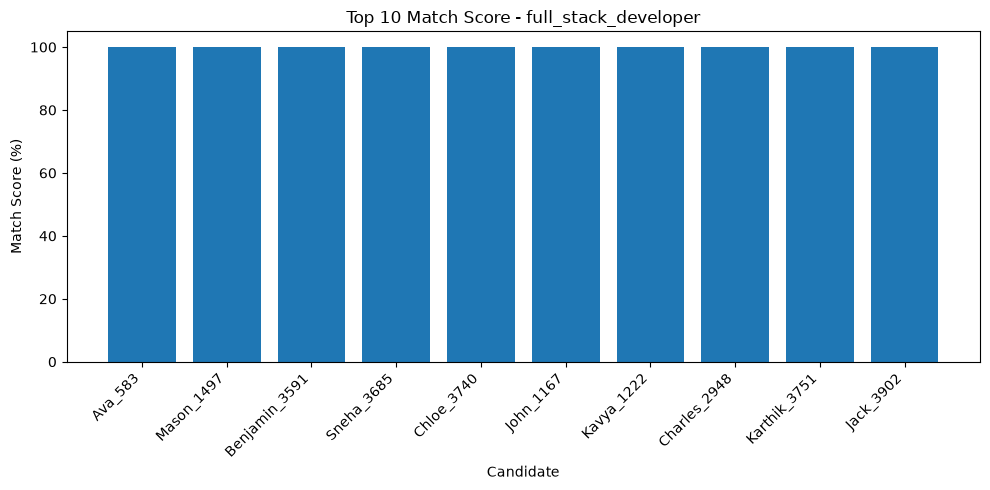

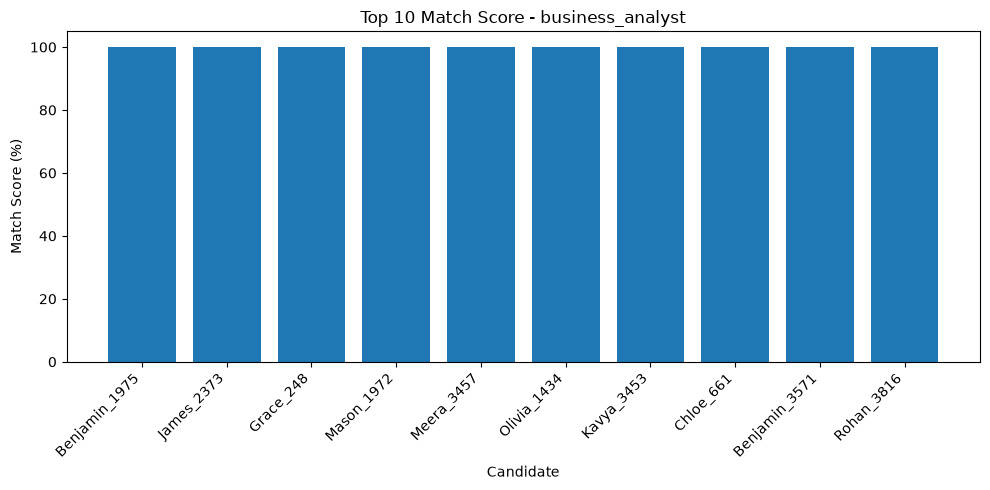

In [45]:
# ============================================================
# STEP 41 : TOP 10 MATCH SCORE VISUALIZATION
# ============================================================

for role in roles:

    top_candidates = final_candidate_ranking(
        role,
        10
    )

    plt.figure(figsize=(10, 5))

    plt.bar(
        top_candidates["candidate_name"],
        top_candidates["match_score"]
    )

    plt.title(
        "Top 10 Match Score - " + role
    )

    plt.xlabel("Candidate")

    plt.ylabel("Match Score (%)")

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.tight_layout()

    plt.show()

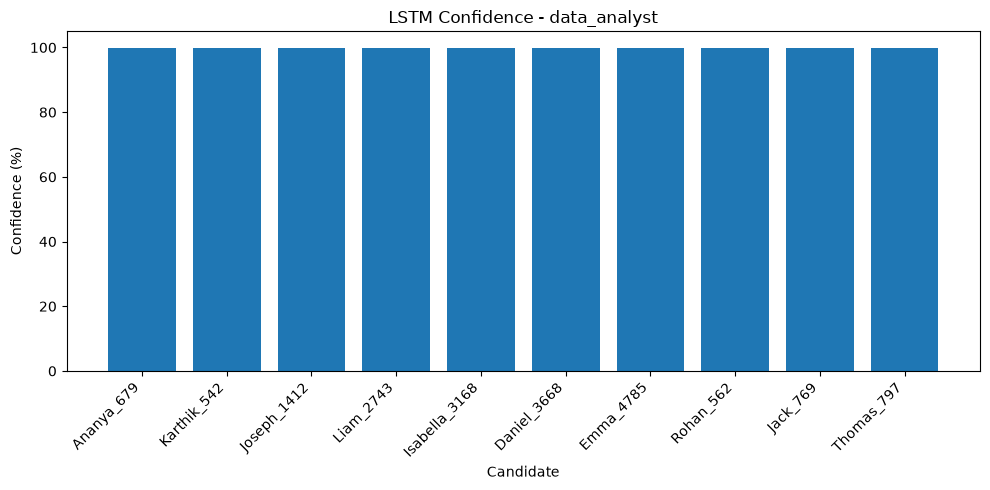

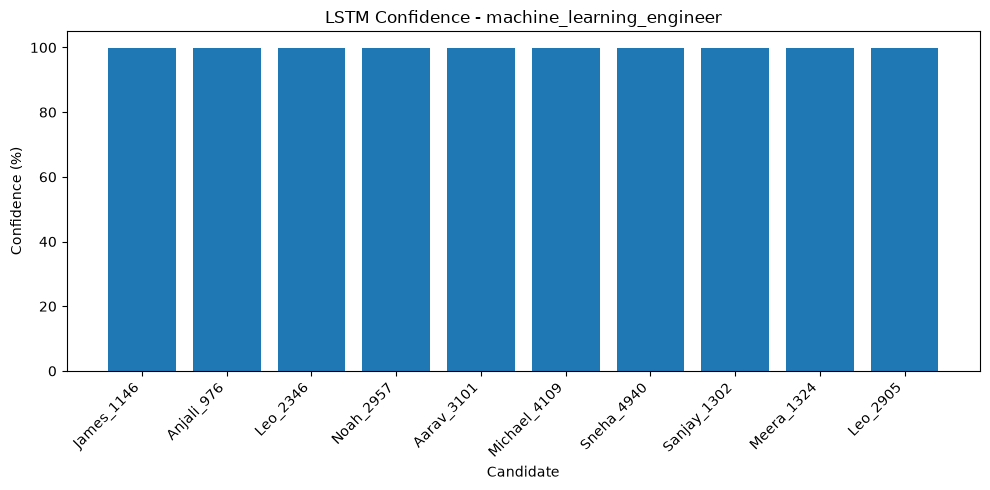

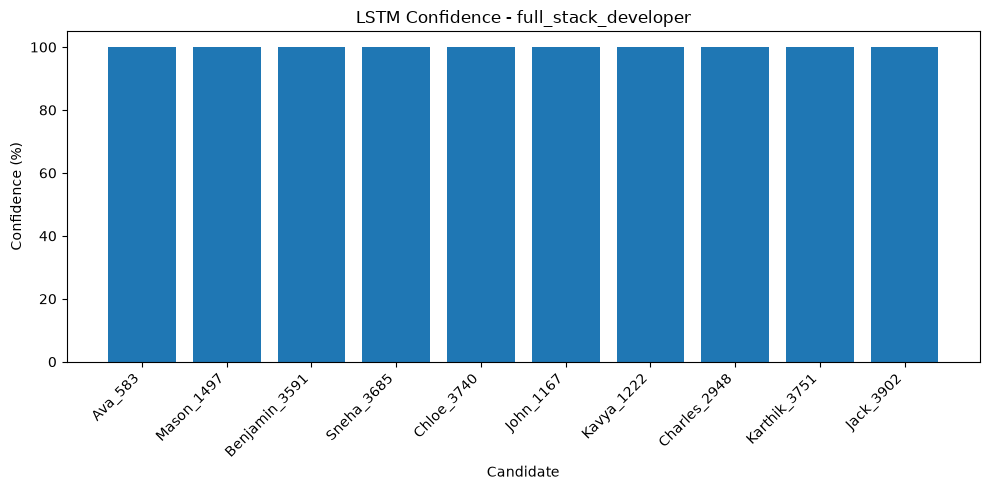

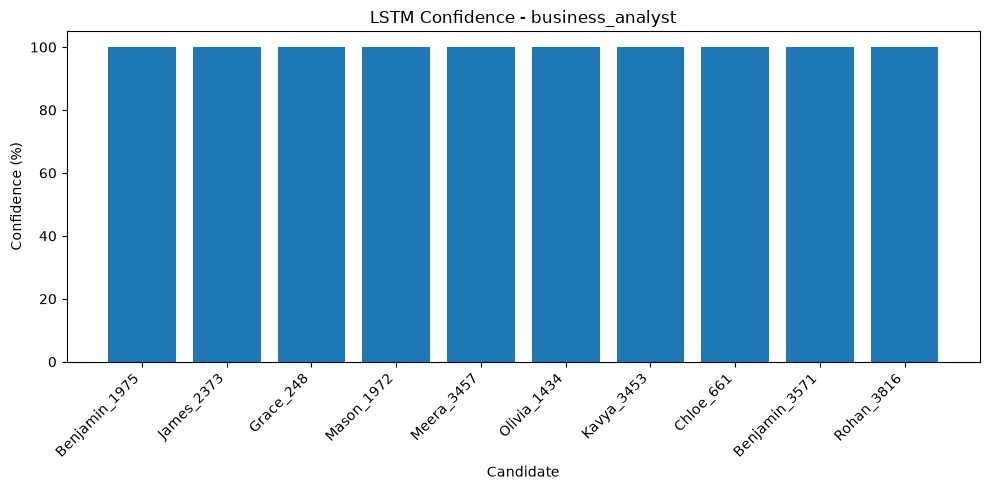

In [46]:
# ============================================================
# STEP 42 : LSTM CONFIDENCE VISUALIZATION
# ============================================================

for role in roles:

    top_candidates = final_candidate_ranking(
        role,
        10
    )

    plt.figure(figsize=(10, 5))

    plt.bar(
        top_candidates["candidate_name"],
        top_candidates["lstm_confidence"]
    )

    plt.title(
        "LSTM Confidence - " + role
    )

    plt.xlabel("Candidate")

    plt.ylabel("Confidence (%)")

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.tight_layout()

    plt.show()

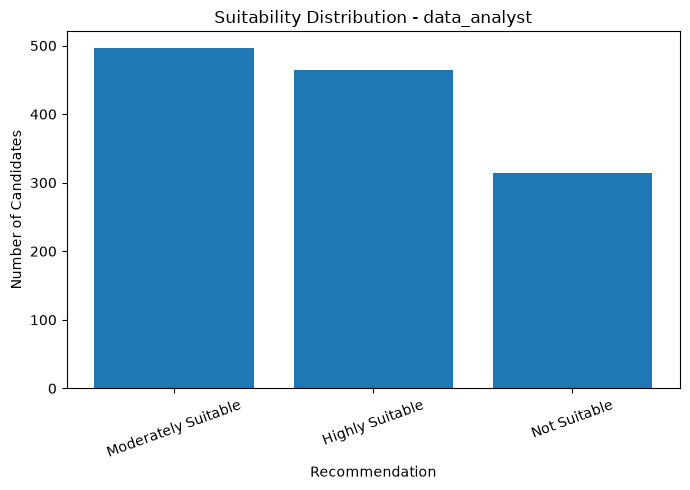

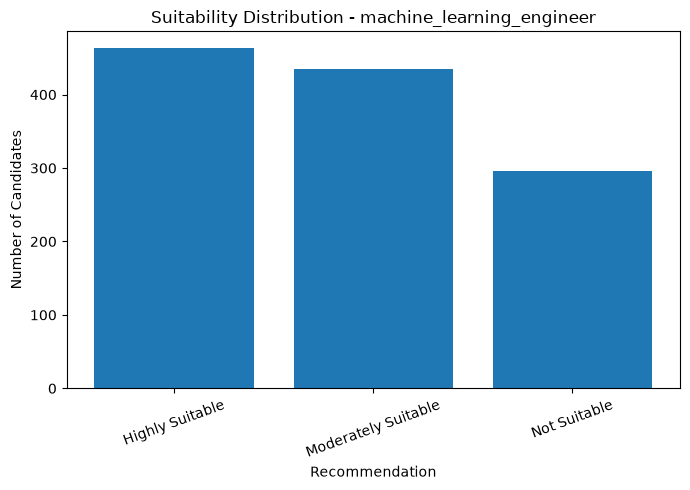

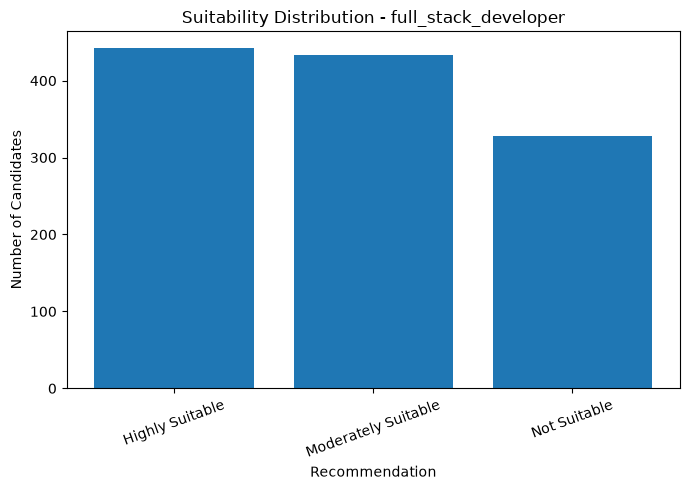

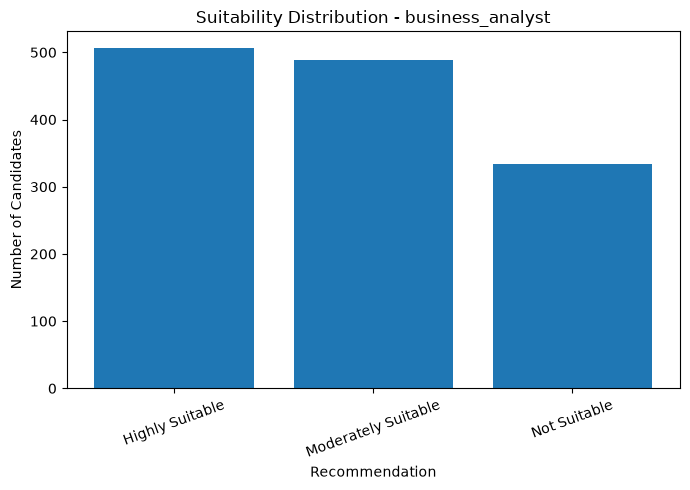

In [47]:
# ============================================================
# STEP 43 : SUITABILITY DISTRIBUTION
# ============================================================

for role in roles:

    role_data = df[
        df["job_role"] == role
    ]

    counts = role_data[
        "recommendation"
    ].value_counts()

    plt.figure(figsize=(7, 5))

    plt.bar(
        counts.index,
        counts.values
    )

    plt.title(
        "Suitability Distribution - " + role
    )

    plt.xlabel("Recommendation")

    plt.ylabel("Number of Candidates")

    plt.xticks(
        rotation=20
    )

    plt.tight_layout()

    plt.show()

In [48]:
# ============================================================
# STEP 44 : SAVE FINAL RESULTS
# ============================================================

all_ranked_candidates = []

for role in roles:

    result = final_candidate_ranking(
        role,
        10
    )

    all_ranked_candidates.append(
        result
    )

final_results = pd.concat(
    all_ranked_candidates,
    ignore_index=True
)

final_results.to_csv(
    "reports/top_candidates.csv",
    index=False
)

print(
    "Final candidate ranking saved successfully"
)

display(final_results)

Final candidate ranking saved successfully


,candidate_id,candidate_name,job_role,skills,matched_skills,missing_skills,match_score,match_category,lstm_prediction,lstm_confidence,recommendation
0,679,Ananya_679,data_analyst,"NumPy, Data Analysis, Machine Learning, Statis...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997269,Highly Suitable
1,542,Karthik_542,data_analyst,"Tableau, Statistics, Machine Learning, Power B...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
2,1412,Joseph_1412,data_analyst,"Data Analysis, Tableau, SQL, NumPy, Machine Le...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
3,2743,Liam_2743,data_analyst,"NumPy, Machine Learning, Statistics, Data Anal...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
4,3168,Isabella_3168,data_analyst,"Data Analysis, Tableau, Machine Learning, Stat...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
5,3668,Daniel_3668,data_analyst,"Excel, Statistics, Data Analysis, Machine Lear...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
6,4785,Emma_4785,data_analyst,"Excel, Data Analysis, Tableau, NumPy, Machine ...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997261,Highly Suitable
7,562,Rohan_562,data_analyst,"Excel, Tableau, Pandas, Power BI, Machine Lear...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997246,Highly Suitable
8,769,Jack_769,data_analyst,"Tableau, Statistics, Machine Learning, SQL, Ex...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997246,Highly Suitable
9,797,Thomas_797,data_analyst,"SQL, Excel, Tableau, Data Analysis, Statistics...","Python, SQL, Power BI, Excel, Statistics, Tabl...",NaN,100.0,Strong Match,2,99.997246,Highly Suitable


In [49]:
# ============================================================
# STEP 45 : PROJECT OUTPUT CHECK
# ============================================================

print("=" * 60)
print("RESUME SCREENING PROJECT COMPLETED")
print("=" * 60)

print(
    "\nDataset:",
    df.shape
)

print(
    "\nModel Accuracy:",
    round(
        accuracy_score_value * 100,
        2
    ),
    "%"
)

print(
    "\nModel File:"
)

print(
    "models/resume_match_model.keras"
)

print(
    "\nTokenizer File:"
)

print(
    "models/tokenizer.pkl"
)

print(
    "\nRanking File:"
)

print(
    "reports/top_candidates.csv"
)

RESUME SCREENING PROJECT COMPLETED

Dataset: (5000, 18)

Model Accuracy: 100.0 %

Model File:
models/resume_match_model.keras

Tokenizer File:
models/tokenizer.pkl

Ranking File:
reports/top_candidates.csv
